# Questions 6 and 7: working notebook (Xave)

This notebook runs on its own: cells 0.1–0.3 are copied unchanged from `assignment2_JL_V2.ipynb`, so every variable (`energy`, `plants`, `groups`, `pct`, …) has the same name as in the shared notebook.

**How to merge it.** Copy everything from **"Bridge from Q5"** onwards into the shared notebook, after Question 5. Do not copy the setup cells.

**What depends on Q4 and Q5.** Search the notebook for these tags:
* `TODO-Q4`: places where I restate a result that Question 4 should derive. Replace the restatement with a reference to Q4, and check the notation matches.
* `TODO-Q5`: places that use the efficiency estimates from Question 5. The bridge cell computes them the way we expect Q5 to, so that this notebook runs now. Swap in her estimates once Q5 is done.

## Setup (copied from the shared notebook; do not paste back)

In [1]:
# 0.1 Packages and data
# Installs any missing package into the kernel you selected (only the first time).
import importlib.util, subprocess, sys
for package in ["numpy", "pandas", "matplotlib", "scipy"]:
    if importlib.util.find_spec(package) is None:
        print(f"Installing {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Finds energy_firms.csv next to the notebook (in data/ or directly), or in a nearby folder
from pathlib import Path

def find_data(name="energy_firms.csv"):
    here = Path.cwd()
    candidates = [here / "data" / name, here / name]
    for folder in list(here.parents)[:2]:
        candidates += [folder / "data" / name, folder / name]
    for path in candidates:
        if path.exists():
            return path
    for path in here.rglob(name):          # search sub-folders of the notebook's folder
        return path
    raise FileNotFoundError(
        f"Could not find {name}. Put it in a folder called 'data' next to this notebook "
        f"(the notebook is running in: {here})."
    )

DATA_PATH = find_data()
print("Data file:", DATA_PATH)
energy = pd.read_csv(DATA_PATH)

group_colours = {"Control": "#52514e", "Treated": "#2a78d6"}
sector_colours = {"Chemicals": "#eb6834", "Textiles": "#1baf7a"}
groups = ["Control", "Treated"]
sectors = ["Chemicals", "Textiles"]

Data file: /Users/xave/Desktop/econ/hw2_insurance_econ/data/energy_firms.csv


In [2]:
# 0.2 Variables we construct
# - group: readable treatment label
# - window: the four periods we compare (pre-programme and three post windows)
# - *_base: each plant's average over the four pre-programme months (-3 to 0)
# - dlog_*: log change relative to the plant's own baseline (0.10 is roughly +10%)
# The data are re-read here so that this cell can be run more than once.

energy = pd.read_csv(DATA_PATH)
energy["group"] = np.where(energy["treated"] == 1, "Treated", "Control")

window_labels = ["Pre (-3 to 0)", "Months 1-3", "Months 4-7", "Months 8-12"]
energy["window"] = pd.cut(energy["month"], bins=[-np.inf, 0, 3, 7, np.inf], labels=window_labels)

baseline = (energy[energy["month"] <= 0]
            .groupby("firm_id")[["output", "labor", "electricity"]]
            .mean()
            .add_suffix("_base"))
energy = energy.join(baseline, on="firm_id")

energy["dlog_E"] = np.log(energy["electricity"] / energy["electricity_base"])
energy["dlog_L"] = np.log(energy["labor"] / energy["labor_base"])
energy["dlog_Q"] = np.log(energy["output"] / energy["output_base"])

# One row per plant: fixed characteristics and baseline (pre-programme) means
plants = (energy[energy["month"] <= 0]
          .groupby(["firm_id", "sector", "treated", "group", "adjust_month"])
          [["output", "labor", "electricity", "output_price", "wage", "energy_price"]]
          .mean()
          .reset_index())
plants["energy_cost_share"] = (plants["energy_price"] * plants["electricity"] /
                               (plants["wage"] * plants["labor"] + plants["energy_price"] * plants["electricity"]))

energy.info()

<class 'pandas.DataFrame'>
RangeIndex: 7680 entries, 0 to 7679
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   firm_id           7680 non-null   str     
 1   sector            7680 non-null   str     
 2   treated           7680 non-null   int64   
 3   month             7680 non-null   int64   
 4   adjust_month      7680 non-null   int64   
 5   labor_adjustable  7680 non-null   int64   
 6   output            7680 non-null   float64 
 7   labor             7680 non-null   float64 
 8   electricity       7680 non-null   float64 
 9   output_price      7680 non-null   float64 
 10  wage              7680 non-null   float64 
 11  energy_price      7680 non-null   float64 
 12  group             7680 non-null   str     
 13  window            7680 non-null   category
 14  output_base       7680 non-null   float64 
 15  labor_base        7680 non-null   float64 
 16  electricity_base  7680 non-null   f

In [3]:
# 0.3 Helper functions
# balance_table: compares treated and control plants variable by variable, in levels and in logs
# (the variables are very skewed, so the log comparison is more informative).
# p-values come from Welch t-tests with one observation per plant.

def balance_table(data, variables):
    rows = []
    for v in variables:
        control = data.loc[data["treated"] == 0, v]
        treated = data.loc[data["treated"] == 1, v]
        rows.append({
            "variable": v,
            "n_control": len(control),
            "mean_control": control.mean(),
            "n_treated": len(treated),
            "mean_treated": treated.mean(),
            "difference": treated.mean() - control.mean(),
            "p_value": stats.ttest_ind(treated, control, equal_var=False).pvalue,
            "diff_logs": np.log(treated).mean() - np.log(control).mean(),
            "p_value_logs": stats.ttest_ind(np.log(treated), np.log(control), equal_var=False).pvalue,
        })
    return pd.DataFrame(rows).round(3)


# pct: turns a mean log change into a percentage change, 100 * (exp(x) - 1)
def pct(x):
    return 100 * (np.exp(x) - 1)


# mean_and_ci_by: mean of a column by group, with a 95% interval across observations
def mean_and_ci_by(data, by, column):
    out = data.groupby(by)[column].agg(["mean", "std", "size"]).reset_index()
    out["se"] = out["std"] / np.sqrt(out["size"])
    out["low"] = out["mean"] - 1.96 * out["se"]
    out["high"] = out["mean"] + 1.96 * out["se"]
    return out

In [4]:
# Extra helper for Q6–Q7: OLS with HC2 robust standard errors, one observation per plant
# (same approach as weighted_effect in 3.3, with several regressors and no weights)

def ols(data, y, x_cols):
    X = np.column_stack([np.ones(len(data))] + [data[c].to_numpy(dtype=float) for c in x_cols])
    yv = data[y].to_numpy(dtype=float)
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ yv
    resid = yv - X @ beta
    leverage = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
    meat = (X * (resid ** 2 / (1 - leverage))[:, None]).T @ X
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    df = len(yv) - X.shape[1]
    t_crit = stats.t.ppf(0.975, df)
    return pd.DataFrame({"coef": beta, "se": se, "low": beta - t_crit * se, "high": beta + t_crit * se,
                         "p_value": 2 * stats.t.sf(np.abs(beta / se), df)},
                        index=["constant"] + list(x_cols)).round(3)

## Bridge from Q5: plant parameters

> **`TODO-Q5`.** This whole section is a placeholder for Question 5. Once her Q5 is in the notebook, **delete these two cells** and make sure her code leaves a plant-level table called `model` (indexed by `firm_id`) with the columns `eta0`, `eta1`, `dlog_eta` and `A`. If she uses other names, rename them here once and leave the rest of Q6–Q7 unchanged.
>
> Things to check against her Q5:
> 1. **Window.** I use months 1–3 for η₁. If she uses a different window (e.g. drops month 1), use hers.
> 2. **Plant-specific or common η₁.** I use each plant's own η₁. If she reports a single treatment effect (difference in differences), Q6–Q7 still need a plant-level η₁; keep this definition and quote her number as the average.
> 3. **The numbers should match:** treated Δlog η ≈ 0.30 (η about 35% higher), control ≈ 0.

Using only the baseline (months −3 to 0) and months 1–3, the model in Q4 gives three plant parameters:

| Parameter | Formula | Why (from Q4) |
|---|---|---|
| $\eta_{0i}$ | $L/E$ at baseline | With both inputs free, no input is wasted: $L = \eta E$ |
| $\eta_{1i}$ | $L/E$ in months 1–3 | Labour is fixed and the plant buys only the electricity it needs: $E = \bar L/\eta_1$ |
| $A_i$ | $q/\sqrt{L}$ at baseline | Production function with $\min\{L,\eta E\} = L$ |

Monthly values are averaged within each window to reduce recording noise.

In [5]:
# >>> TODO-Q5: placeholder for Question 5's estimates. Replace with hers. <<<
def window_means(months):
    return (energy[energy["month"].isin(months)]
            .groupby("firm_id")[["output", "labor", "electricity"]].mean())

short_run = window_means(range(1, 4))     # months 1-3: labour still fixed for every cohort
medium_run = window_means(range(9, 13))   # months 9-12: held out; every cohort can adjust labour

model = plants.set_index("firm_id").copy()          # baseline means, prices, energy cost share
model["eta0"] = model["labor"] / model["electricity"]
model["eta1"] = short_run["labor"] / short_run["electricity"]
model["dlog_eta"] = np.log(model["eta1"] / model["eta0"])
model["A"] = model["output"] / np.sqrt(model["labor"])
# <<< end of TODO-Q5 placeholder >>>

# Change in efficiency by group, and the part attributable to consulting (treated minus control)
eta_t = model.loc[model["treated"] == 1, "dlog_eta"]
eta_c = model.loc[model["treated"] == 0, "dlog_eta"]
eta_did = eta_t.mean() - eta_c.mean()
eta_se = np.sqrt(eta_t.var() / len(eta_t) + eta_c.var() / len(eta_c))
print(f"Change in eta, treated: {pct(eta_t.mean()):.1f}%   control: {pct(eta_c.mean()):.1f}%")
print(f"Attributable to consulting: {pct(eta_did):.1f}% "
      f"(95% CI {pct(eta_did - 1.96 * eta_se):.1f}% to {pct(eta_did + 1.96 * eta_se):.1f}%)")

Change in eta, treated: 35.0%   control: 0.0%
Attributable to consulting: 35.0% (95% CI 33.8% to 36.1%)


## 6. Does your explanation predict more than the initial pattern?

A convincing mechanism should generate additional, testable implications. Derive predictions from your explanation and choose new tables, figures or comparisons to investigate each of the following.

    (a) The magnitude of later choices. Does profit maximisation predict plants’ later output and input quantities accurately? Use only baseline observations and months 1–3 to recover any required plant parameters. Make predictions before comparing them with the held-out observations in months 9–12. Examine discrepancies as well as fit.

    (b) Production and electricity. Is the observed change in production large enough to account for the later electricity response, given the efficiency change you estimated? Derive a quantitative criterion and identify which plants meet it. A matching sign alone is not sufficient.

    (c) Differences across firms. According to your mechanism, which pre-intervention characteristics should predict the strongest later electricity responses? Derive and investigate that prediction. Distinguish differences in the size of the efficiency improvement from differences in firms’ responses to a given improvement.

    (d) Input relationships and timing. What relationships between labor and electricity changes should your explanation imply? Do these differ when you compare later observations with baseline rather than with the initial post-intervention period? Investigate these relationships and whether the timing of responses is consistent with the institutional setting.

Explain what each piece of evidence establishes. Distinguish predictions tested against additional observations from identities built from the same quantities. Consider at least one alternative explanation, what would distinguish it from yours, and any limits of the available evidence.

### 6(a) The magnitude of later choices
Each plant has its own $A_i$,and prices which can be found in the baseline and $\eta_{1i}$  from months 1-3. The formula above can then be used to estimate the plant's output, labour, and electricity once labour can be adjusted. The prediction for each plant is then compared with the actual output, electricity, and labour of each plant from months nine through twelve after labour has been allowed to be adjusted for all plants. Analysis will be in changes compared to own baseline due to the large difference in sizes of plants.

**Prediction** The plants in the treatment group are expected to increase labour on average by about 48%, output by 22% and electricity by 10% according to the model's estimates from data in the baseline period and months 1-3. Control plants are expected to stay at their baseline, so their errors show how much recording noise alone produces. 

In [6]:
# 6(a) Profit-maximising choices when both inputs adjust (see Q4 / 6.0)
def optimum(A, p, w, c, eta):
    k = w + c / eta
    x = (p * A / (2 * k)) ** 2
    return pd.DataFrame({"output": A * np.sqrt(x), "labor": x, "electricity": x / eta,
                         "profit": (p * A) ** 2 / (4 * k)})

p, w, c = model["output_price"], model["wage"], model["energy_price"]

# Test of baseline optimality, not used to calibrate anything: revenue should be twice variable cost
model["revenue_over_cost"] = p * model["output"] / (w * model["labor"] + c * model["electricity"])
print("Baseline revenue / variable cost (model predicts exactly 2):")
display(model.groupby("group")["revenue_over_cost"].describe()[["count", "mean", "std", "min", "max"]].round(3))

# Predictions for months 9-12 from baseline and months 1-3 only
predicted = optimum(model["A"], p, w, c, model["eta1"])
quantities = ["output", "labor", "electricity"]
pred_change = np.log(predicted[quantities] / model[quantities])
obs_change = np.log(medium_run[quantities] / model[quantities])
error = obs_change - pred_change          # log(observed / predicted)
tr = model["treated"] == 1                # treated plants, used in 6(a)-6(d)

rows = []
for g in groups:
    idx = model["group"] == g
    for v in quantities:
        e = error.loc[idx, v]
        rows.append({
            "group": g, "variable": v, "plants": idx.sum(),
            "predicted_change_pct": pct(pred_change.loc[idx, v].mean()),
            "observed_change_pct": pct(obs_change.loc[idx, v].mean()),
            "mean_error_pct": pct(e.mean()),
            "error_sd_pct": 100 * e.std(),
            "share_within_5pct": (e.abs() < np.log(1.05)).mean(),
            "corr_pred_obs": np.corrcoef(pred_change.loc[idx, v], obs_change.loc[idx, v])[0, 1],
        })
fit_table = pd.DataFrame(rows).round(2)
display(fit_table)


Baseline revenue / variable cost (model predicts exactly 2):


,count,mean,std,min,max
group,,,,,
Control,240.0,2.002,0.023,1.928,2.054
Treated,240.0,2.002,0.024,1.939,2.075


,group,variable,plants,predicted_change_pct,observed_change_pct,mean_error_pct,error_sd_pct,share_within_5pct,corr_pred_obs
0,Control,output,240,0.08,-0.09,-0.17,2.39,0.94,-0.36
1,Control,labor,240,0.17,0.11,-0.06,2.90,0.92,0.37
2,Control,electricity,240,0.14,0.06,-0.08,2.17,0.98,0.35
3,Treated,output,240,21.61,21.63,0.01,2.44,0.97,0.92
4,Treated,labor,240,47.89,47.76,-0.09,2.79,0.91,0.97
5,Treated,electricity,240,9.55,9.46,-0.08,2.26,0.98,0.97


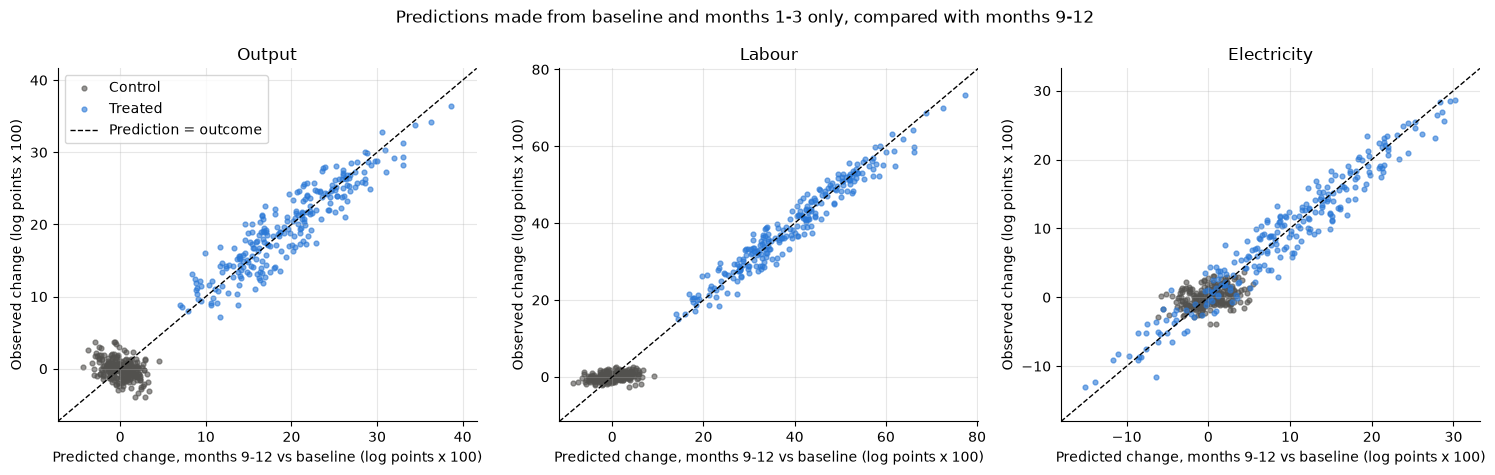

In [7]:
# 6(a) Predicted vs observed change from baseline, one point per plant
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
names = {"output": "Output", "labor": "Labour", "electricity": "Electricity"}
for ax, v in zip(axes, quantities):
    for g in groups:
        idx = model["group"] == g
        ax.scatter(100 * pred_change.loc[idx, v], 100 * obs_change.loc[idx, v],
                   s=12, alpha=0.6, color=group_colours[g], label=g)
    lims = [100 * min(pred_change[v].min(), obs_change[v].min()) - 3,
            100 * max(pred_change[v].max(), obs_change[v].max()) + 3]
    ax.plot(lims, lims, "--", color="black", linewidth=1, label="Prediction = outcome")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Predicted change, months 9-12 vs baseline (log points x 100)")
    ax.set_ylabel("Observed change (log points x 100)")
    ax.set_title(names[v])
axes[0].legend()
fig.suptitle("Predictions made from baseline and months 1-3 only, compared with months 9-12")
fig.tight_layout()
plt.show()

Mean prediction error, treated plants (%), by sector and staffing-review month:


output  labor  electricity
sector    adjust_month                            
Chemicals 4              -0.14  -0.48        -0.18
          6              -0.01  -0.17        -0.41
          8               0.11   0.23         0.14
Textiles  4               0.36   0.13         0.21
          6               0.12   0.32         0.35
          8              -0.36  -0.57        -0.58

Does the electricity error depend on cost share, the efficiency gain or sector? (treated plants)


,coef,se,low,high,p_value
constant,2.101,0.913,0.303,3.900,0.022
energy_cost_share,-1.325,1.071,-3.435,0.786,0.218
dlog_eta,-4.159,2.066,-8.230,-0.089,0.045
chemicals,-0.056,0.307,-0.661,0.549,0.855


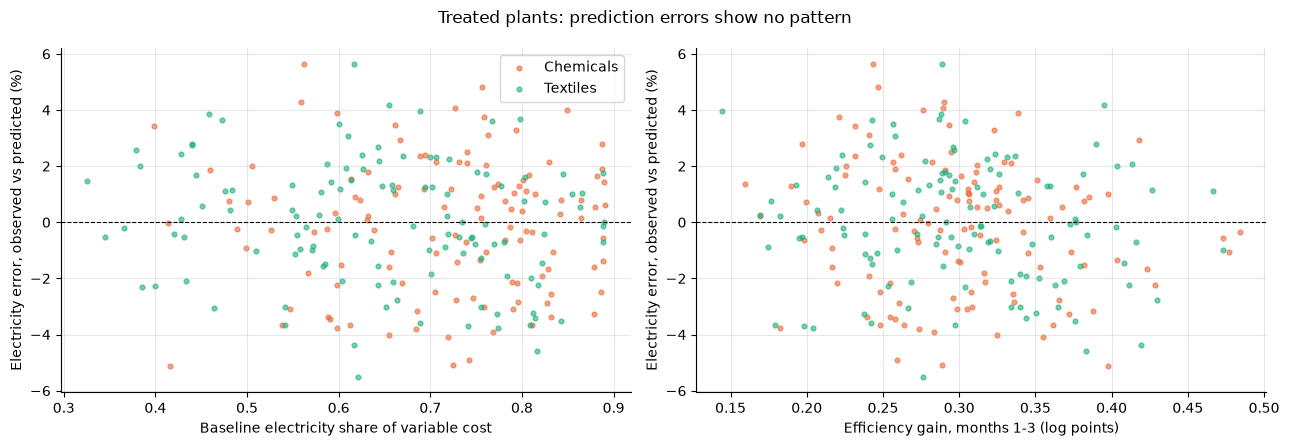

In [8]:
# 6(a) Discrepancies: are treated plants' errors related to anything the model leaves out?
treated_err = error[tr].join(model.loc[tr, ["sector", "adjust_month", "energy_cost_share", "dlog_eta"]])
treated_err[quantities] *= 100

print("Mean prediction error, treated plants (%), by sector and staffing-review month:")
display(treated_err.groupby(["sector", "adjust_month"])[quantities].mean().round(2))

print("Does the electricity error depend on cost share, the efficiency gain or sector? (treated plants)")
display(ols(treated_err.assign(chemicals=(treated_err["sector"] == "Chemicals").astype(int)),
            "electricity", ["energy_cost_share", "dlog_eta", "chemicals"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (col, label) in zip(axes, [("energy_cost_share", "Baseline electricity share of variable cost"),
                                   ("dlog_eta", "Efficiency gain, months 1-3 (log points)")]):
    for s in sectors:
        d = treated_err[treated_err["sector"] == s]
        ax.scatter(d[col], d["electricity"], s=12, alpha=0.6, color=sector_colours[s], label=s)
    ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
    ax.set_xlabel(label)
    ax.set_ylabel("Electricity error, observed vs predicted (%)")
axes[0].legend()
fig.suptitle("Treated plants: prediction errors show no pattern")
fig.tight_layout()
plt.show()

**What 6(a) establishes.**
* **The baseline is consistent with profit maximisation.** Within both the treatment and control groups, firms were maximizing profits according to the requirements of the technology as seen by the revenue being about 2.00 times variable cost.
* **The predictions fit.** The predictions for electricity, labour, and output had a mean error of less than 0.2% and between 91-98% of plants are within 5% of their predicted output.
* **Discrepancies look like noise.** The errors predicting electricity have not been found to vary with sector or cost share


> **`TODO-Q5`.** If her η₁ estimates differ from mine, re-run and check these numbers. They are quoted from the placeholder estimates.

### 6(b) Production and electricity

**Criterion.** Once labour can adjust, $L = \eta E$ and $q = A\sqrt{L}$, so $E = q^2/(A^2\eta)$. Relative to baseline, and with η at its post-consulting level,
$$\Delta\log E = 2\,\Delta\log q - \Delta\log\eta .$$
Since $A$ is constant, it drops out of the difference.

Electricity ends up **above** its pre-programme level only if output has grown by more than half the efficiency gain:
$$\Delta\log q > \tfrac12\,\Delta\log\eta .$$

From the answer to Question 5, with a 35% efficiency increase, output has to raise by at least $\sqrt{1.35}-1 \approx 16\%$ before electricity use returns to baseline.

The criterion combines output (months 9–12) with η from months 1–3. It tests that the efficiency gain is present and that the technology holds.

In [9]:
# 6(b) Criterion: electricity rises above baseline if dlog q > 1/2 dlog eta
model["dlogQ_later"] = obs_change["output"]
model["dlogL_later"] = obs_change["labor"]
model["dlogE_later"] = obs_change["electricity"]
model["dlogQ_required"] = 0.5 * model["dlog_eta"]
model["dlogE_implied"] = 2 * model["dlogQ_later"] - model["dlog_eta"]
model["meets_criterion"] = model["dlogQ_later"] > model["dlogQ_required"]
model["electricity_above_baseline"] = model["dlogE_later"] > 0

# Treated vs control averages (log points x 100), and the difference attributable to consulting
cols = ["dlogQ_later", "dlogQ_required", "dlogE_implied", "dlogE_later"]
avg = model.groupby("group")[cols].mean().mul(100)
avg.loc["Treated - Control"] = avg.loc["Treated"] - avg.loc["Control"]
display(avg.round(2))

# Plant by plant: does the criterion sort plants correctly?
display(pd.crosstab(model.loc[tr, "meets_criterion"], model.loc[tr, "electricity_above_baseline"],
                    rownames=["output grew by more than half the eta gain"],
                    colnames=["electricity above baseline in months 9-12"], margins=True))



,dlogQ_later,dlogQ_required,dlogE_implied,dlogE_later
group,,,,
Control,-0.09,0.01,-0.21,0.06
Treated,19.58,15.00,9.15,9.04
Treated - Control,19.67,14.99,9.36,8.98


electricity above baseline in months 9-12,False,True,All
output grew by more than half the eta gain,,,
False,31,10,41
True,9,190,199
All,40,200,240


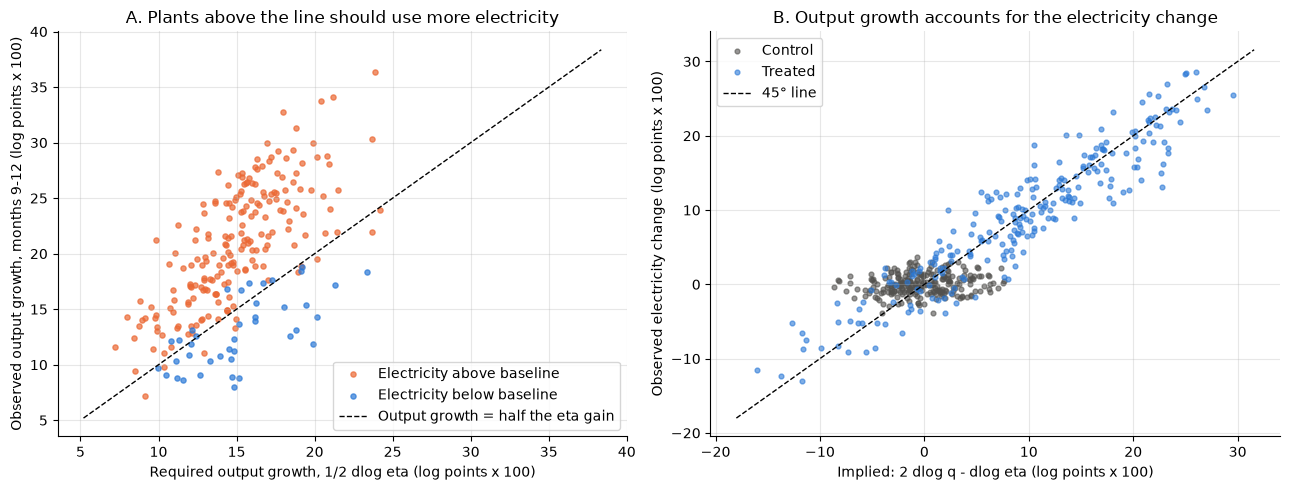

In [10]:
# 6(b) Figure: required vs actual output growth (left); implied vs observed electricity change (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
d = model[tr]
ax = axes[0]
for above, colour, label in [(True, "#eb6834", "Electricity above baseline"),
                             (False, "#2a78d6", "Electricity below baseline")]:
    s = d[d["electricity_above_baseline"] == above]
    ax.scatter(100 * s["dlogQ_required"], 100 * s["dlogQ_later"], s=14, alpha=0.7, color=colour, label=label)
lims = [100 * d[["dlogQ_required", "dlogQ_later"]].min().min() - 2,
        100 * d[["dlogQ_required", "dlogQ_later"]].max().max() + 2]
ax.plot(lims, lims, "--", color="black", linewidth=1, label="Output growth = half the eta gain")
ax.set_xlabel("Required output growth, 1/2 dlog eta (log points x 100)")
ax.set_ylabel("Observed output growth, months 9-12 (log points x 100)")
ax.set_title("A. Plants above the line should use more electricity")
ax.legend()

ax = axes[1]
for g in groups:
    s = model[model["group"] == g]
    ax.scatter(100 * s["dlogE_implied"], 100 * s["dlogE_later"], s=12, alpha=0.6, color=group_colours[g], label=g)
lims = [100 * model[["dlogE_implied", "dlogE_later"]].min().min() - 2,
        100 * model[["dlogE_implied", "dlogE_later"]].max().max() + 2]
ax.plot(lims, lims, "--", color="black", linewidth=1, label="45° line")
ax.set_xlabel("Implied: 2 dlog q - dlog eta (log points x 100)")
ax.set_ylabel("Observed electricity change (log points x 100)")
ax.set_title("B. Output growth accounts for the electricity change")
ax.legend()
fig.tight_layout()
plt.show()

**What 6(b) establishes.**
* **The average suggests that output growth is large enough to account for electricity responses.** Consulting raised η by about 35%, requiring output to grow by 15 log points for electricity to exceed the baseline. The treated output was found to grow by 19.7 log points compared to the control.
* **Which plants meet the goal.** The criterion classifies 221 of the 240 plants correctly, with 190 above baseline and 31 below. The  slope in panel B is slightly below the expected 1, which can be expected due to recording noise.
* **What this shows.** The efficiency gain measured in months 1-3 persists in months 9-12.

### 6(c) Differences across firms

**Derivation.** Let $g_i = \eta_{1i}/\eta_{0i}$ be the plant's efficiency gain. Let $s_i = cE/(wL+cE)$ be electricity's share of variable cost at baseline, a pre-intervention characteristic. The cost of a unit of effective input changes by the factor $k_1/k_0 = (1-s) + s/g$. Using $x^* \propto k^{-2}$ and $E = x/\eta$:
$$\Delta\log E_{\text{later}} = -2\log\!\Big(1 - s + \tfrac{s}{g}\Big) - \log g .$$

* **Response to a given improvement** (fixed $g>1$). The response rises with $s$. Electricity ends up above baseline when
$$s > s^*(g) = \frac{\sqrt g}{1+\sqrt g}\quad(\approx 0.54 \text{ for } g = 1.35).$$
Where electricity is a large part of costs, an efficiency gain lowers the plant's marginal cost a lot. Output and labour expand so much that they outweigh the saving per unit.
* **Size of the improvement** (fixed $s$). A larger $g$ raises later electricity only if $s > g/(1+g)$. At lower cost shares a bigger gain *reduces* electricity. The two effects therefore have to be separated: $g$ comes from months 1–3, $s$ from baseline.

**Prediction.** The derivation suggests plants with higher baseline electricity costs show the largest later rise, regardless of sector due to the technology being the same functin.


In [11]:
# 6(c) Later electricity response, cost share and efficiency gain (treated plants)
d = model[tr].copy()
d["chemicals"] = (d["sector"] == "Chemicals").astype(int)
d["dlogE_later_pct"] = 100 * d["dlogE_later"]

# Is the size of the improvement related to the cost share? (separates the two channels)
r, p_value = stats.pearsonr(d["energy_cost_share"], d["dlog_eta"])
print(f"Correlation of baseline cost share with efficiency gain: {r:.2f} (p-value {p_value:.2f})")

print("Regression of the later electricity change (log points x 100) on pre-intervention cost share,")
print("the efficiency gain from months 1-3, and sector:")
display(ols(d, "dlogE_later_pct", ["energy_cost_share", "dlog_eta", "chemicals"]))

# Quintiles of cost share: observed vs model-predicted later change
d["share_quintile"] = pd.qcut(d["energy_cost_share"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
d["threshold"] = np.sqrt(np.exp(d["dlog_eta"])) / (1 + np.sqrt(np.exp(d["dlog_eta"])))
display(d.groupby("share_quintile", observed=True).agg(
    plants=("dlog_eta", "size"),
    mean_cost_share=("energy_cost_share", "mean"),
    share_chemicals=("chemicals", "mean"),
    eta_gain_pct=("dlog_eta", lambda x: pct(x.mean())),
    predicted_change_pct=("electricity", lambda x: pct(pred_change.loc[x.index, "electricity"].mean())),
    observed_change_pct=("dlogE_later", lambda x: pct(x.mean())),
    share_above_threshold=("energy_cost_share", lambda x: (x > d.loc[x.index, "threshold"]).mean()),
    share_electricity_up=("electricity_above_baseline", "mean"),
).round(2))

Correlation of baseline cost share with efficiency gain: 0.01 (p-value 0.82)
Regression of the later electricity change (log points x 100) on pre-intervention cost share,
the efficiency gain from months 1-3, and sector:


,coef,se,low,high,p_value
constant,-39.108,1.351,-41.770,-36.446,0.000
energy_cost_share,63.902,1.467,61.012,66.791,0.000
dlog_eta,16.043,3.265,9.610,22.476,0.000
chemicals,-0.366,0.320,-0.996,0.264,0.253


,plants,mean_cost_share,share_chemicals,eta_gain_pct,predicted_change_pct,observed_change_pct,share_above_threshold,share_electricity_up
share_quintile,,,,,,,,
Q1 (lowest),48,0.47,0.33,34.81,-3.83,-3.60,0.29,0.17
Q2,48,0.61,0.40,35.17,4.43,4.36,1.00,1.00
Q3,48,0.70,0.54,34.51,10.30,10.38,1.00,1.00
Q4,48,0.77,0.62,33.58,15.32,15.15,1.00,1.00
Q5 (highest),48,0.85,0.60,36.94,23.51,22.92,1.00,1.00


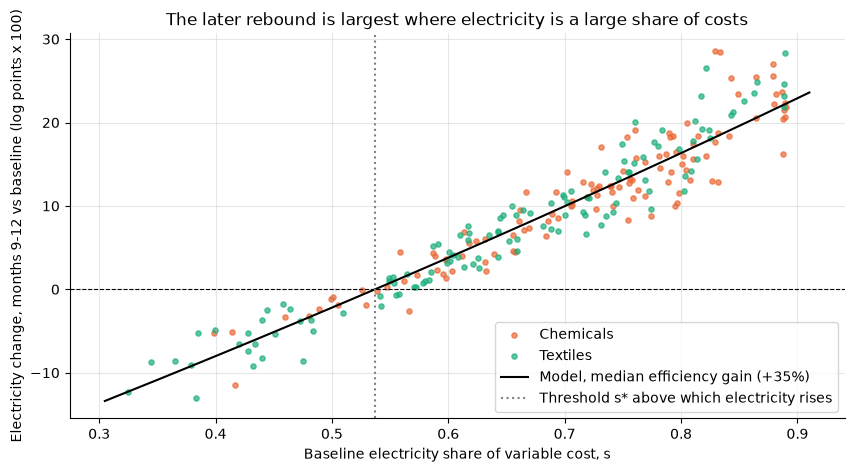

In [12]:
# 6(c) Figure: later electricity change against baseline cost share, with the model's curve
g_med = np.exp(d["dlog_eta"].median())
s_grid = np.linspace(d["energy_cost_share"].min() - 0.02, d["energy_cost_share"].max() + 0.02, 200)
curve = -2 * np.log(1 - s_grid + s_grid / g_med) - np.log(g_med)

fig, ax = plt.subplots()
for sct in sectors:
    sd = d[d["sector"] == sct]
    ax.scatter(sd["energy_cost_share"], 100 * sd["dlogE_later"], s=14, alpha=0.7,
               color=sector_colours[sct], label=sct)
ax.plot(s_grid, 100 * curve, color="black", linewidth=1.5,
        label=f"Model, median efficiency gain (+{100 * (g_med - 1):.0f}%)")
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.axvline(np.sqrt(g_med) / (1 + np.sqrt(g_med)), linestyle=":", color="grey",
           label="Threshold s* above which electricity rises")
ax.set_xlabel("Baseline electricity share of variable cost, s")
ax.set_ylabel("Electricity change, months 9-12 vs baseline (log points x 100)")
ax.set_title("The later rebound is largest where electricity is a large share of costs")
ax.legend()
plt.show()

**What 6(c) establishes.**
* **The cost share predicts the later response.** Later changes in electricity rise with the baseline cost-share with -3.6% in the lowest quintile to +22.9% in the highest. 
* **Size of Efficiency Gain is Unrelated to Cost Share.** The gain in efficiency varies little across plants (about 35% in every quintile) showing that the size of the gain is not reliant on the cost share. This small variation in efficiency gain explains less of the spread than cost share.

### 6(d) Input relationships and timing
**How Labour and Electricty Comparisons** Labour is not expected to move before the plant's review month and move only in that month, as there are no adjustment costs once the commitment ends. Electricity is expected to move twice, when η rises in month 1 and in the adjustment month. Control plants are not predicted to move at all.

| Comparison | Labour | Electricity | Relationship |
|---|---|---|---|
| Months 1–3 vs baseline | $0$ (fixed) | $-\Delta\log\eta$ | Electricity falls with labour unchanged |
| Months 9–12 vs months 1–3 | $\Delta\log L$ | $\Delta\log L$ | **Slope 1, intercept 0**: η is unchanged, so $L/E$ stays fixed |
| Months 9–12 vs baseline | $\Delta\log L$ | $\Delta\log L - \Delta\log\eta_i$ | **Slope 1 on labour and −1 on the plant's own η gain.** Without that control, the slope is not 1, because the gain varies across plants and is correlated with expansion |

,group,comparison,model_predicts,intercept,coef_labour [95% CI],coef_eta_gain [95% CI]
0,Control,Months 9-12 vs months 1-3,"no change: noise only, no slope expected",0.000,"-0.19 [-0.40, 0.02]",
1,Control,Months 9-12 vs baseline,"no change: noise only, no slope expected",0.001,"0.09 [-0.08, 0.27]",
2,Control,"Months 9-12 vs baseline, with plant's eta gain","no change: noise only, no slope expected",0.000,"0.17 [-0.01, 0.35]","-0.17 [-0.26, -0.08]"
3,Treated,Months 9-12 vs months 1-3,"slope 1, intercept 0",0.001,"1.00 [0.98, 1.02]",
4,Treated,Months 9-12 vs baseline,not one for one: eta gain is omitted,-0.161,"0.64 [0.60, 0.69]",
5,Treated,"Months 9-12 vs baseline, with plant's eta gain","labour 1, eta gain -1, intercept 0",-0.015,"0.97 [0.95, 1.00]","-0.91 [-0.95, -0.87]"


Correlation of labour expansion with the eta gain (treated): 0.64


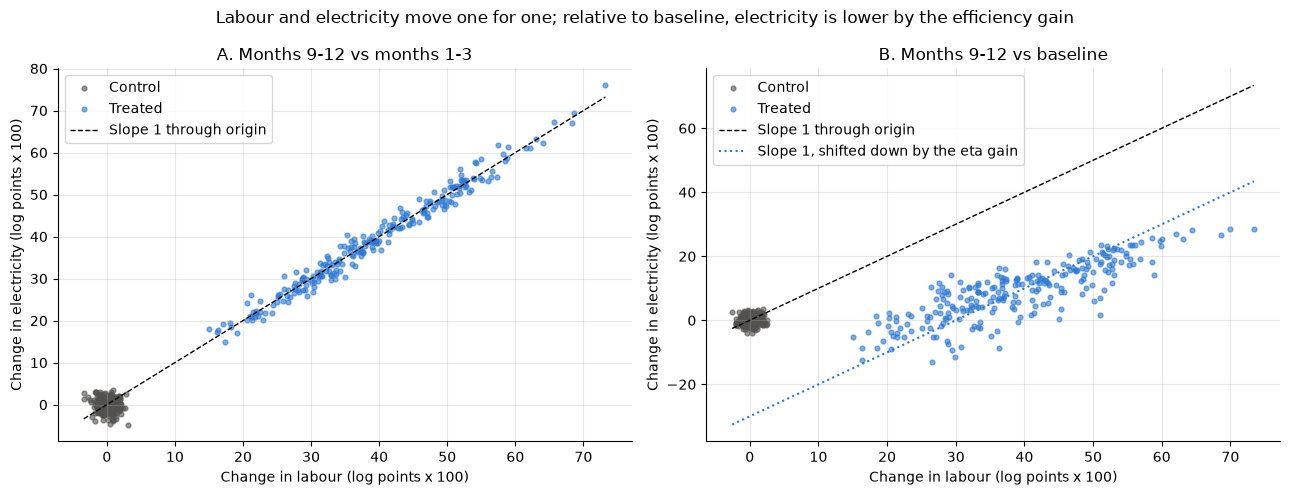

In [13]:
# 6(d) Labour and electricity changes: relative to months 1-3 vs relative to baseline
model["dlogL_vs_sr"] = np.log(medium_run["labor"] / short_run["labor"])
model["dlogE_vs_sr"] = np.log(medium_run["electricity"] / short_run["electricity"])

rows = []
specs = [("Months 9-12 vs months 1-3", "dlogE_vs_sr", ["dlogL_vs_sr"], "slope 1, intercept 0"),
         ("Months 9-12 vs baseline", "dlogE_later", ["dlogL_later"], "not one for one: eta gain is omitted"),
         ("Months 9-12 vs baseline, with plant's eta gain", "dlogE_later", ["dlogL_later", "dlog_eta"],
          "labour 1, eta gain -1, intercept 0")]
for g in groups:
    m = model[model["group"] == g]
    for label, y, xs, prediction in specs:
        res = ols(m, y, xs)
        if g != "Treated":   # eta never changes for control plants, so nothing should move
            prediction = "no change: noise only, no slope expected"
        row = {"group": g, "comparison": label, "model_predicts": prediction,
               "intercept": res.loc["constant", "coef"]}
        for x in xs:
            row[f"coef_{x.split('_')[0]}"] = f"{res.loc[x, 'coef']:.2f} [{res.loc[x, 'low']:.2f}, {res.loc[x, 'high']:.2f}]"
        rows.append(row)
display(pd.DataFrame(rows).rename(columns={"coef_dlogL": "coef_labour [95% CI]", "coef_dlog": "coef_eta_gain [95% CI]"})
        .fillna("").round(3))
print(f"Correlation of labour expansion with the eta gain (treated): "
      f"{model.loc[tr, 'dlogL_later'].corr(model.loc[tr, 'dlog_eta']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, (label, x, y) in zip(axes, [("A. Months 9-12 vs months 1-3", "dlogL_vs_sr", "dlogE_vs_sr"),
                                     ("B. Months 9-12 vs baseline", "dlogL_later", "dlogE_later")]):
    for g in groups:
        m = model[model["group"] == g]
        ax.scatter(100 * m[x], 100 * m[y], s=12, alpha=0.6, color=group_colours[g], label=g)
    xs = np.array([100 * model[x].min(), 100 * model[x].max()])
    ax.plot(xs, xs, "--", color="black", linewidth=1, label="Slope 1 through origin")
    if "baseline" in label:
        ax.plot(xs, xs - 100 * model.loc[tr, "dlog_eta"].mean(), ":", color=group_colours["Treated"],
                linewidth=1.5, label="Slope 1, shifted down by the eta gain")
    ax.set_xlabel("Change in labour (log points x 100)")
    ax.set_ylabel("Change in electricity (log points x 100)")
    ax.set_title(label)
    ax.legend()
fig.suptitle("Labour and electricity move one for one; relative to baseline, electricity is lower by the efficiency gain")
fig.tight_layout()
plt.show()

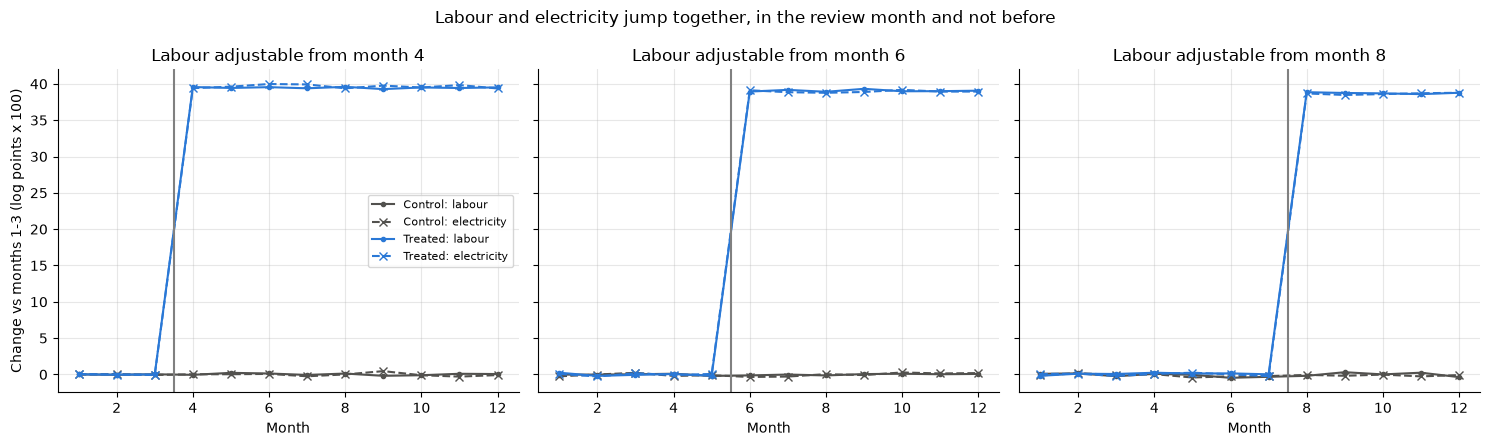

,mean_monthly_change_pct,sd_pct,plant_months
months_since_review,,,
-3,0.02,1.84,240
-2,0.03,1.90,240
-1,-0.11,1.87,240
0,39.17,11.64,240
1,0.00,1.97,240
2,-0.07,1.84,240
3,0.05,1.87,240


In [14]:
# 6(d) Timing: months relative to each plant's staffing-review month, changes vs months 1-3
ev = energy[energy["month"] >= 1].join(short_run.add_suffix("_sr"), on="firm_id")
ev["months_since_review"] = ev["month"] - ev["adjust_month"]
ev["dlogL_vs_sr"] = np.log(ev["labor"] / ev["labor_sr"])
ev["dlogE_vs_sr"] = np.log(ev["electricity"] / ev["electricity_sr"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, cohort in zip(axes, [4, 6, 8]):
    for g in groups:
        e = ev[(ev["adjust_month"] == cohort) & (ev["group"] == g)].groupby("month")[["dlogL_vs_sr", "dlogE_vs_sr"]].mean()
        ax.plot(e.index, 100 * e["dlogL_vs_sr"], marker="o", markersize=3, color=group_colours[g],
                label=f"{g}: labour")
        ax.plot(e.index, 100 * e["dlogE_vs_sr"], marker="x", linestyle="--", color=group_colours[g],
                label=f"{g}: electricity")
    ax.axvline(cohort - 0.5, color="grey")
    ax.set_title(f"Labour adjustable from month {cohort}")
    ax.set_xlabel("Month")
axes[0].set_ylabel("Change vs months 1-3 (log points x 100)")
axes[0].legend(fontsize=8)
fig.suptitle("Labour and electricity jump together, in the review month and not before")
fig.tight_layout()
plt.show()

# Size of the month-to-month change in labour, by month relative to the review month (treated plants)
ev = ev.sort_values(["firm_id", "month"])
ev["dlogL_step"] = ev.groupby("firm_id")["labor"].transform(lambda s: np.log(s).diff())
step = (ev[(ev["treated"] == 1) & ev["months_since_review"].between(-3, 3)]
        .groupby("months_since_review")["dlogL_step"].agg(["mean", "std", "size"]).mul([100, 100, 1]))
step.columns = ["mean_monthly_change_pct", "sd_pct", "plant_months"]
display(step.round(2))

**What 6(d) establishes.**
* **Support for the model's prediciton** The model's predictions are supported in comparing both the electricity and labour changes from months 9-12 to 1-3 as well as at baseline. This means, compared with baseline, electricty is lower than labour by the plant's efficiency gain. 
* **The timing supports this** Labour does not change in the month's before the adjustment. In the adjustment month it increase by about 39 log points and does not move afterwards, understood to be the labour constraint change.

### 6(e) Alternative explanations and limits

**Alternative Explanation NEED TO COMPLETE STILL BUT THINKING MAYBE THE DIFFERENCE IN gROUPS WASnt random or thAt THERE WAS A SHOCK EFFECT AND WE ARE JUST ASSUMING THE SHOCK WOULD SHOW IN CONTROL BUT ISNT** 

**Limits.**
* The data is synthetic, so its close fit is expected if the model is correct. The checks show the mechanism is consistent with the data, not that it is the only possible one.
* Prices never vary, so plants response to prices cannot be considered. With no price variation and only 12 months, we cannot study longer-run responses (capital, entry or exit).


## 7. Evaluate a further efficiency improvement

Suppose a follow-up programme could raise each treated plant’s current η by a further 20%, with Ai and prices unchanged. This is additional to the original intervention; there are no observations from the proposed programme.
Predict output, labor, electricity and operating profits with labor first fixed at the current medium-run level, then freely adjustable. Compare both scenarios with the same no-follow-up baseline. Aggregate the results and examine differences across plants. Explain why extrapolating the original percentage effect might be misleading. Profits exclude the unknown cost of delivering consulting.

*Optional policy extension.* After the original intervention, what plant-specific electricity levy would keep medium-run electricity use at or below its pre-intervention level? Set the levy to zero where none is needed. Let plants reoptimise; report output, profits and tax revenue. Explain why this is not an estimate of an optimal environmental tax or necessarily a feasible uniform policy.

### 7.1 Set-up **`TODO-Q5`.** "Each treated plant's current η" is $\eta_{1i}$ from the bridge cell, so these results move with her Q5 estimates.
* **No-follow-up baseline (common to both scenarios).** The baseline is refersto the profit maximization predictions from the estimated model when labour and electricity can change with the current η (with the original intervention but not the 20% increase). 
* **Follow up estimations.** For treated plants, η is raised by 20% with Aᵢ and prices unchanged. In Scenario A, labour is held at its baseline level and only electricity is re-optimised; in Scenario B, both labour and electricity are re-optimised. Both scenarios are evaluated as changes relative to the same baseline.
        **η after the follow-up:** $\eta_2 = 1.2\,\eta_1$. $A$ and prices are unchanged.

* **Untreated plants.** Untreated plants receive no follow-up, so their outcomes are identical across the baseline and both scenarios.

* **Scenario A: labour fixed at the medium-run level $L_1 = x_1$.** Cheaper effective input means the plants would increase profits by expanding but labour is capped. Output is unchanged and profit rises by what the electricty bill saved. Electricity falls by exactly $1 - 1/1.2 = 16.7\%$

* **Scenario B: labour free.** Each plant re-optimises both inputs. The lower effective cost of energy reduces marginal cost, so labour and output rise above the baseline. Whether electricity rises depends on the plant: the expansion outweighs the per-unit saving when the current electricity cost share $s_1$ exceeds $\sqrt{1.2}/(1+\sqrt{1.2}) \approx 0.523$, which holds for most treated plants. Profit rises by at least as much as in Scenario A, since the plant could always keep Scenario A's labour level.

In [41]:
# 7. Follow-up programme: eta rises by a further 20% for treated plants
t = model[tr].copy()
pt, wt, ct = t["output_price"], t["wage"], t["energy_price"]
t["eta2"] = 1.2 * t["eta1"]

no_follow_up = optimum(t["A"], pt, wt, ct, t["eta1"])

labour_fixed = pd.DataFrame({"output": no_follow_up["output"], "labor": no_follow_up["labor"],
                             "electricity": no_follow_up["labor"] / t["eta2"]})
labour_fixed["profit"] = pt * labour_fixed["output"] - wt * labour_fixed["labor"] - ct * labour_fixed["electricity"]

labour_free = optimum(t["A"], pt, wt, ct, t["eta2"])

scenarios = {"Predicted at estimated η₁ (no follow-up)": no_follow_up, "η increased 20%, labour fixed": labour_fixed, "η increased 20%, labour free": labour_free}
cols = ["output", "labor", "electricity", "profit"]

# Aggregate across the 240 treated plants
agg = pd.DataFrame({name: s[cols].sum() for name, s in scenarios.items()}).T
agg_pct = 100 * (agg / agg.loc["Predicted at estimated η₁ (no follow-up)"] - 1)
print("Totals across treated plants (output in batches, labour in blocks, electricity in MWh, profit in CU, per month):")
display(agg.round(0))
print("Change relative to no follow-up (%):")
display(agg_pct.round(1))


Totals across treated plants (output in batches, labour in blocks, electricity in MWh, profit in CU, per month):


,output,labor,electricity,profit
Predicted at estimated η₁ (no follow-up),23692.0,62593.0,1168912.0,279932451.0
"η increased 20%, labour fixed",23692.0,62593.0,974093.0,312074048.0
"η increased 20%, labour free",26478.0,78391.0,1220883.0,316435294.0


Change relative to no follow-up (%):


,output,labor,electricity,profit
Predicted at estimated η₁ (no follow-up),0.0,0.0,0.0,0.0
"η increased 20%, labour fixed",0.0,0.0,-16.7,11.5
"η increased 20%, labour free",11.8,25.2,4.4,13.0


181 of 240 plants use more electricity (those with current electricity cost share above 0.523)


,s_current,electricity_change_pct,profit_change_pct
sector,,,
Chemicals,0.65,5.18,12.31
Textiles,0.58,2.47,10.84


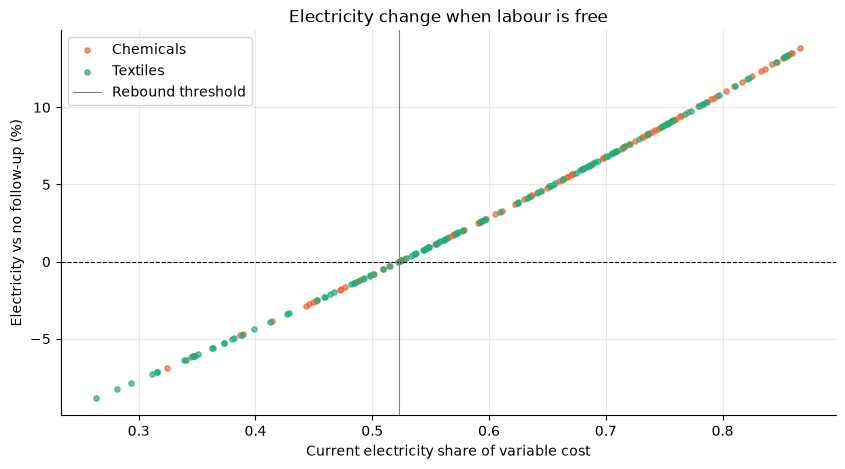

In [ ]:
# 7. Differences across plants (labour free): who uses more electricity after the follow-up?
t["s_current"] = (ct / t["eta1"]) / (wt + ct / t["eta1"])   # electricity share of variable cost now
t["electricity_change_pct"] = 100 * (labour_free["electricity"] / no_follow_up["electricity"] - 1)
t["profit_change_pct"] = 100 * (labour_free["profit"] / no_follow_up["profit"] - 1)
threshold = np.sqrt(1.2) / (1 + np.sqrt(1.2))

print(f"{(t['electricity_change_pct'] > 0).sum()} of {len(t)} plants use more electricity "
      f"(those with current electricity cost share above {threshold:.3f})")
display(t.groupby("sector")[["s_current", "electricity_change_pct", "profit_change_pct"]].mean().round(2))

fig, ax = plt.subplots()
for sct in sectors:
    sd = t[t["sector"] == sct]
    ax.scatter(sd["s_current"], sd["electricity_change_pct"], s=14, alpha=0.7, color=sector_colours[sct], label=sct)
ax.axhline(0, linestyle="--", color="black", linewidth=0.8)
ax.axvline(threshold, color="grey", linewidth=0.8, label="Rebound threshold")
ax.set_xlabel("Current electricity share of variable cost")
ax.set_ylabel("Electricity vs no follow-up (%)")
ax.set_title("Electricity change when labour is free")
ax.legend()
plt.show()


In [18]:
# 7. Why extrapolating the original effect would mislead: naive scaling vs the model
orig_eta = model.loc[tr, "dlog_eta"].mean() - model.loc[~tr, "dlog_eta"].mean()
orig_E_sr = model.loc[tr, "dlog_eta"].mul(-1).mean()                         # months 1-3, treated
orig_E_mr = model.loc[tr, "dlogE_later"].mean() - model.loc[~tr, "dlogE_later"].mean()
scale = np.log(1.2) / orig_eta

display(pd.DataFrame({
    "original programme (observed)": [pct(orig_eta), pct(orig_E_sr), pct(orig_E_mr)],
    "naive: scale original effect to a 20% eta gain": [20.0, pct(orig_E_sr * scale), pct(orig_E_mr * scale)],
    "model prediction for the follow-up": [20.0, agg_pct.loc["η increased 20%, labour fixed", "electricity"],
                                           agg_pct.loc["η increased 20%, labour free", "electricity"]],
}, index=["eta change %", "electricity, labour fixed %", "electricity, labour free %"]).round(1))

,original programme (observed),naive: scale original effect to a 20% eta gain,model prediction for the follow-up
eta change %,35.0,20.0,20.0
"electricity, labour fixed %",-25.9,-16.7,-16.7
"electricity, labour free %",9.4,5.6,4.4


### 7.2 Interpretation  After swapping eta in Q5 (`TODO-Q5`), re-run and update them from the tables above.
All observations below are for the 240 treated plants relative to the no follow up baseline per month. 
* **Labour fixed.** Output and labour are unchanged while electricity falls by about 16.7% at every plant (195,000 MWh per month total). Operating profit rises 11.5%. The savings only last while labour is fixed.
* **Labour free.** Plants expant. Output increases by 11.8%, labour by 25.2% and electicity by 4.4% above the no follow up level. The follow-up is then seen to increase medium-run electricity use.

* **Differences across plants.** Whether electricity use increases or decreases depends on the electricity cost share. The 20% of plants with the lowest electricity cost share save 4.3% of electricity while those with the highest share use 11.1% more. Chemical plants are more represented in this high electricty cose share group than the Texiles plants.

* **Why extrapolating the original effect misleads.** The results depend on the horizon being analyzed. The original program reduced electricity use by 26% when labour was fixed, however when labour could be adjusted electricty use increased by 9.4%. Plants are different now. Better efficiency only lowers electricity costs. After the first programme, electricity is a smaller share of each plant's costs (0.68 → 0.62 on average), so another 20% gain saves them less money and they expand less. Scaling up the original effect predicts electricity rises 5.6%; the model predicts 4.4%.
